# Шум RSGM на GPU: как было и как стало (для чайников)

Этот ноутбук шаг за шагом объясняет, что происходит в `RSGM.loss` и почему раньше видеокарта простаивала. Каждая ячейка исполняемая и печатает, **где лежит каждый тензор**: форму, тип и устройство.

**Коротко:**

| | было (`noise="cpu"`) | стало (`noise="device"`) |
|---|---|---|
| где считается шум | CPU, float64 (`hp/models/igso3.py`) | GPU, float32 (`hp/models/igso3_gpu.py`) |
| копий CPU↔GPU за шаг | 5 | 0 |
| точность target | ~1e-11 (кроме дыры при больших s) | ~1e-6 (дыр нет) |
| шаг обучения на mps | 1× | в 1.8–2.7 раза быстрее (глава 7) |

План:
1. Что вообще делает loss: шум, угол, тепловое ядро, target.
2. Как было: путь `noise="cpu"` строчка за строчкой.
3. Почему так было сделано: float64, которого нет на MPS.
4. Как стало: несколько трюков, благодаря которым хватает float32.
5. Новый путь `noise="device"` строчка за строчкой.
6. Проверка точности.
7. Проверка скорости.
8. Подводные камни и как этим пользоваться.

In [1]:
import os

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # до импорта torch

import math
import time

import matplotlib.pyplot as plt
import roma
import torch

from hp.models import build_model, igso3, igso3_gpu
from hp.models.rsgm import exp_frame, move

DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
B, J = 512, 19  # поз в батче, суставов в позе
print("device:", DEVICE, "| torch", torch.__version__)


def where(name, x):
    """Где лежит тензор: форма, тип, устройство."""
    print(f"  {name:8s} {str(tuple(x.shape)):16s} {str(x.dtype).replace('torch.', ''):8s} {x.device}")


def sync():
    if DEVICE == "mps":
        torch.mps.synchronize()
    elif DEVICE.startswith("cuda"):
        torch.cuda.synchronize()


def timed(fn, repeats=20):
    """Медианное время fn() в мс; устройство синхронизируется до и после, иначе мы мерили бы только постановку в очередь."""
    fn(), fn()
    sync()
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        sync()
        times.append(time.perf_counter() - start)
    return 1000 * sorted(times)[len(times) // 2]

device: mps | torch 2.13.0


## 1. Что вообще делает loss

**Поза** — это 19 вращений, по одному на сустав, то есть тензор `[19, 3, 3]`. Батч поз имеет форму `[B, 19, 3, 3]`.

**Зашумление.** Каждый сустав поворачиваем на случайный угол ω вокруг случайной оси u:

$$x_t = x_0 \cdot \exp(\omega\, \hat u)$$

Чем больше «время» t ∈ [0, 1], тем больше углы. Время пересчитывается во внутреннее время броуновского движения $s(t) = \int_0^t \beta$, а дальше всё зависит только от s.

**Задача сети:** по зашумлённой позе $x_t$ угадать, в какую сторону и насколько сильно поворачивать обратно к данным. Это и есть **score**.

In [2]:
model = build_model("rsgm", num_joints=J, beta_f=10.0, noise="cpu")  # beta_f как в config/models/rsgm.yaml

print("t       ->  s(t)       типичный угол ω (медиана)")
for t in [0.001, 0.01, 0.1, 0.5, 1.0]:
    s = float(model.s(torch.tensor(t, dtype=torch.float64)))
    omega = model.angles.sample(torch.full((20_000,), s))
    print(f"{t:<7} ->  {s:.2e}   {omega.median():.4f} рад = {math.degrees(omega.median()):6.2f}°")

t       ->  s(t)       типичный угол ω (медиана)
0.001   ->  6.00e-06   0.0038 рад =   0.22°
0.01    ->  5.10e-04   0.0348 рад =   1.99°
0.1     ->  5.01e-02   0.3416 рад =  19.57°
0.5     ->  1.25e+00   1.6318 рад =  93.50°
1.0     ->  5.00e+00   2.2775 рад = 130.49°


При t = 0.001 углы порядка десятых градуса (почти без шума). При t = 1 это ~100°, то есть поза почти полностью случайна.

### Какое распределение у угла: IGSO(3)

Угол ω не нормальный: он распределён по **тепловому ядру SO(3)** $f(\omega; s)$, умноженному на объём $(1-\cos\omega)/\pi$. Это аналог гауссианы для вращений. Сэмплер (`AngleSampler`) берёт угол из этого распределения.

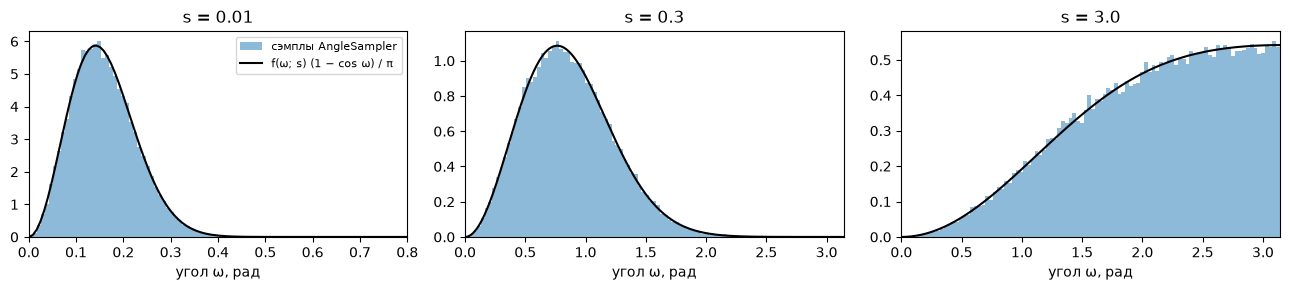

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, s in zip(axes, [0.01, 0.3, 3.0]):
    omega = model.angles.sample(torch.full((50_000,), s))
    grid = torch.linspace(1e-3, math.pi, 400, dtype=torch.float64)
    pdf = igso3.log_density(grid, torch.full_like(grid, s)).exp() * (1 - torch.cos(grid)) / math.pi
    ax.hist(omega.numpy(), bins=100, density=True, alpha=0.5, label="сэмплы AngleSampler")
    ax.plot(grid, pdf, "k", label="f(ω; s) (1 − cos ω) / π")
    ax.set_xlim(0, min(math.pi, 8 * math.sqrt(s)))
    ax.set_title(f"s = {s}")
    ax.set_xlabel("угол ω, рад")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Target, на котором учится сеть

$f$ зависит только от угла, поэтому score переходной плотности направлен по оси u, а его величина равна производной по углу:

$$\nabla \log p(x_t \mid x_0) = \frac{d}{d\omega}\log f(\omega; s)\cdot u$$

При малых s эта производная огромная, ≈ −ω/s ~ 1/√s. Поэтому в лосс идёт score, умноженный на $\mathrm{std}(s) = \sqrt{1-e^{-s}} \approx \sqrt{s}$ (так называемый **std trick**). Так target получается порядка 1.

In [4]:
print(f"{'s':>8}  {'типичный ω':>10}  {'score = dlogf/dω':>17}  {'std·score = target':>19}")
for s in [6e-6, 1e-3, 0.1, 1.0, 5.0]:
    w = model.angles.sample(torch.full((20_000,), s)).median()
    score = float(igso3.d_log_density(w, torch.tensor(s, dtype=torch.float64)))
    std = math.sqrt(-math.expm1(-s))
    print(f"{s:8.0e}  {float(w):10.4f}  {score:17.2f}  {std * score:19.3f}")

       s  типичный ω   score = dlogf/dω   std·score = target
   6e-06      0.0038            -629.29               -1.541
   1e-03      0.0492             -49.15               -1.554
   1e-01      0.4834              -4.79               -1.479
   1e+00      1.4726              -1.34               -1.069
   5e+00      2.2992              -0.03               -0.030


Видно, что score доходит до сотен, а target всегда порядка 1. Это важно для третьей главы: **большие значения сами по себе для float32 не проблема**.

## 2. Как было: `noise="cpu"`

Вот что происходило на каждом шаге обучения:

```
DataLoader (CPU) ──①──> GPU: pose
                         │
                         └──②──> CPU, float64: x0
                                   CPU: t, s, ω, u, x_t, target   <- всё последовательно, GPU ждёт
                         GPU <──③④⑤── x_t, target, t (float32)
                         GPU: сеть, backward, Adam
```

Повторим это руками, с теми же строчками, что в `RSGM.noised_cpu`. После каждой строки печатается, где лежит результат.

In [5]:
model_old = build_model("rsgm", num_joints=J, beta_f=10.0, noise="cpu").to(DEVICE).train()

pose_cpu = roma.random_rotmat(B * J).reshape(B, J, 3, 3)  # так батч отдаёт DataLoader: на CPU
pose = pose_cpu.to(DEVICE)  # trainer._unpack
print("trainer:  копия ① CPU -> GPU")
where("pose", pose)

print("\nRSGM.noised_cpu:")
t = model_old.loss_times(torch.rand(B, dtype=torch.float64))
where("t", t)
s = model_old.s(t)[:, None].expand(B, J)  # одно время на позу, общее для всех суставов
where("s", s)
omega = model_old.angles.sample(s)  # угол из таблицы IGSO(3)
where("omega", omega)
axis = igso3.random_axes((B, J))  # равномерная ось на сфере
where("axis", axis)
x0 = move(pose, "cpu", torch.float64)
print("  ^ копия ② GPU -> CPU: та же поза, которая только что приехала на GPU")
where("x0", x0)
xt = exp_frame(x0, omega[..., None] * axis)  # x_t = x0 · exp(ω u)
where("xt", xt)
target = model_old.std(t)[:, None, None] * igso3.d_log_density(omega, s)[..., None] * axis
where("target", target)
xt, target, t = (move(v, DEVICE, torch.float32) for v in (xt, target, t))
print("  ^ копии ③④⑤ CPU -> GPU")
for name, v in (("xt", xt), ("target", target), ("t", t)):
    where(name, v)

print("\nсеть:")
where("score", model_old.score(xt, t))

trainer:  копия ① CPU -> GPU
  pose     (512, 19, 3, 3)  float32  mps:0

RSGM.noised_cpu:
  t        (512,)           float64  cpu
  s        (512, 19)        float64  cpu
  omega    (512, 19)        float64  cpu
  axis     (512, 19, 3)     float64  cpu
  ^ копия ② GPU -> CPU: та же поза, которая только что приехала на GPU
  x0       (512, 19, 3, 3)  float64  cpu
  xt       (512, 19, 3, 3)  float64  cpu
  target   (512, 19, 3)     float64  cpu
  ^ копии ③④⑤ CPU -> GPU
  xt       (512, 19, 3, 3)  float32  mps:0
  target   (512, 19, 3)     float32  mps:0
  t        (512,)           float32  mps:0

сеть:
  score    (512, 19, 3)     float32  mps:0


**Сами копии небольшие:** поза весит `512·19·9·4 байт` ≈ 350 КБ. Медленно не из-за шины, а потому что **всё между ② и ③ идёт на CPU, а GPU в это время ничего не делает**. Замерим, сколько это занимает.

In [6]:
opt = torch.optim.Adam(model_old.parameters(), lr=2e-4)
xt, target, t = model_old.noised_cpu(pose)


def net_only():
    opt.zero_grad()
    ((model_old.score(xt, t) * model_old.std(t)[:, None, None] - target) ** 2).sum((1, 2)).mean().backward()
    opt.step()


def full_step_old():
    opt.zero_grad()
    model_old.loss(pose).backward()
    opt.step()


noise_ms, net_ms, full_ms = timed(lambda: model_old.noised_cpu(pose)), timed(net_only), timed(full_step_old)
print(f"шум на CPU + копии  : {noise_ms:6.2f} ms")
print(f"сеть (fwd+bwd+Adam) : {net_ms:6.2f} ms")
print(f"весь шаг            : {full_ms:6.2f} ms   -> шум занимает {noise_ms / full_ms:.0%} шага")

шум на CPU + копии  :   5.02 ms
сеть (fwd+bwd+Adam) :   2.13 ms
весь шаг            :   7.42 ms   -> шум занимает 68% шага


## 3. Почему так было сделано: float64

В `igso3.py` всё считается во float64. На CPU это нормально, а вот **у Apple GPU (MPS) float64 нет вообще**:

In [7]:
if DEVICE == "mps":
    try:
        torch.zeros(3, dtype=torch.float64, device="mps")
        print("float64 на mps работает")
    except Exception as e:
        print("float64 на mps:", type(e).__name__, "-", str(e).split("\n")[0])
else:
    print(f"на {DEVICE} float64 есть; на mps его нет")

float64 на mps: TypeError - Cannot convert a MPS Tensor to float64 dtype as the MPS framework doesn't support float64. Please use float32 instead.


Отсюда цепочка: *формуле нужен float64 → на MPS его нет → считаем на CPU → копируем туда и обратно*.

**А нужен ли float64 на самом деле?** Возьмём ту же формулу из `igso3.d_log_density` и посчитаем её во float32. Эталон — новое ядро во float64 (оно совпадает с 50-значным mpmath до 1e-13, см. `tests/test_igso3_gpu.py`).

In [8]:
def old_formula(omega, s):
    """Формула igso3.d_log_density, но в dtype входа (там она всегда float64)."""
    k = igso3.IMAGES.to(omega)
    shifted = omega[..., None] + 2 * math.pi * k
    weight = (-1) ** k.abs() * torch.exp(-(shifted**2 - omega[..., None] ** 2) / (2 * s[..., None]))
    bracket = (weight * shifted).sum(-1)
    d_bracket = (weight * (1 - shifted * 2 * math.pi * k / s[..., None])).sum(-1)
    return -omega / s + d_bracket / bracket - 0.5 / torch.tan(omega / 2)


print(f"{'s':>5} {'ω':>7}   {'точно':>12} {'старая формула fp32':>20}")
for s in [0.001, 5.0]:
    for w in [1e-6, 1e-4, 1e-2, 0.5]:
        exact = float(igso3_gpu.d_log_density(torch.tensor(w, dtype=torch.float64), torch.tensor(s, dtype=torch.float64)))
        fp32 = float(old_formula(torch.tensor([w]), torch.tensor([s]))[0])
        print(f"{s:5} {w:7.0e}   {exact:12.6f} {fp32:20.6f}")

    s       ω          точно  старая формула fp32
0.001   1e-06      -0.001000             0.000000
0.001   1e-04      -0.099992            -0.099609
0.001   1e-02      -9.999167            -9.999176
0.001   5e-01    -499.958159          -499.958130
  5.0   1e-06      -0.000000         36188.562500
  5.0   1e-04      -0.000004            -3.828125
  5.0   1e-02      -0.000381            -0.000916
  5.0   5e-01      -0.018366            -0.018366


При s = 0.001 float32 почти везде справляется. А при **s = 5 и малых ω он выдаёт мусор** (тысячи вместо ~0). Есть и вторая слабость, в построении таблицы сэмплера: $1-\cos\omega$ при малых ω.

In [9]:
w = torch.tensor([1e-4, 3e-4, 1e-3])
print("ω          :", w.tolist())
print("1 − cos ω  fp32:", (1 - torch.cos(w)).tolist(), " <- при ω = 1e-4 ровно 0")
print("1 − cos ω  fp64:", (1 - torch.cos(w.double())).tolist())

ω          : [9.999999747378752e-05, 0.0003000000142492354, 0.0010000000474974513]
1 − cos ω  fp32: [0.0, 5.960464477539063e-08, 4.76837158203125e-07]  <- при ω = 1e-4 ровно 0
1 − cos ω  fp64: [4.99999974756804e-09, 4.50000039453613e-08, 5.000000058430487e-07]


Значит, проблема не во float32 вообще, а в **двух конкретных местах формулы**. Если их переписать, float32 хватает. Дальше разберём, как именно.

## 4. Как стало: трюки, чтобы хватило float32

### Трюк 1: устранимая особенность 1/ω

В производной два слагаемых, каждое ≈ 1/ω: одно из суммы образов, другое из $-\tfrac12\cot(\omega/2)$. По отдельности при ω = 1e-6 они около миллиона, а их разность — маленькое гладкое число. float32 хранит ~7 значащих цифр, так что от разности ничего не остаётся.

Решение: посчитать разность **аналитически**. $g(\omega) = 1/\omega - \tfrac12\cot(\omega/2) = \omega/12 + \omega^3/720 + \dots$ — это гладкая функция, и при малых ω её можно считать рядом Тейлора.

In [10]:
import mpmath

w = torch.tensor([1e-6, 1e-4, 1e-2, 0.3])
a, b = 1 / w, 0.5 / torch.tan(w / 2)
with mpmath.workdps(50):  # эталон: 50 значащих цифр (во fp64 то же вычитание при ω = 1e-6 тоже теряет точность)
    exact = [float(1 / mpmath.mpf(float(x)) - mpmath.cot(mpmath.mpf(float(x)) / 2) / 2) for x in w]
print(f"{'ω':>7} {'1/ω':>12} {'½cot(ω/2)':>12} {'разность fp32':>14} {'g(ω) Тейлор fp32':>17} {'точно':>12}")
for i in range(len(w)):
    print(f"{w[i]:7.0e} {a[i]:12.1f} {b[i]:12.1f} {a[i] - b[i]:14.3e} {igso3_gpu._g(w)[i]:17.3e} {exact[i]:12.3e}")

      ω          1/ω    ½cot(ω/2)  разность fp32  g(ω) Тейлор fp32        точно
  1e-06    1000000.0    1000000.0      0.000e+00         8.333e-08    8.333e-08
  1e-04      10000.0      10000.0      0.000e+00         8.333e-06    8.333e-06
  1e-02        100.0        100.0      8.240e-04         8.333e-04    8.333e-04
  3e-01          3.3          3.3      2.504e-02         2.504e-02    2.504e-02


### Трюк 2: образы суммируем парами

Ядро записано как сумма «образов» гауссианы: k = −4…4 (угол ω, ω ± 2π, …). При больших s слагаемые k и −k почти равны по модулю и противоположны по знаку. Вся сумма пропорциональна ω (она нечётна по ω), а отдельные слагаемые порядка 0.1. Вот как это выглядит при s = 5 и ω = 1e-6:

In [11]:
s, w = torch.tensor(5.0), torch.tensor(1e-6)
k = torch.arange(-4, 5).float()
shifted = w + 2 * math.pi * k
terms = (-1) ** k.abs() * shifted * torch.exp(-(shifted**2 - w**2) / (2 * s))
for ki, ti in zip(k, terms):
    print(f"  k = {int(ki):+d}:  {float(ti):+.8f}")
b64, _ = igso3_gpu._pairs(w[None].double(), s[None].double())  # B = сумма / ω, в замкнутой форме
b32, _ = igso3_gpu._pairs(w[None], s[None])
print(f"\nсумма по слагаемым, fp32 : {float(terms.sum()):+.4e}")
print(f"пары в замкнутой форме, fp32: {float(w * b32[0]):+.4e}")
print(f"точно (fp64)               : {float(w.double() * b64[0]):+.4e}")

  k = -4:  -0.00000000
  k = -3:  +0.00000000
  k = -2:  -0.00000174
  k = -1:  +0.12124233
  k = +0:  +0.00000100
  k = +1:  -0.12124211
  k = +2:  +0.00000174
  k = +3:  -0.00000000
  k = +4:  +0.00000000

сумма по слагаемым, fp32 : +1.2219e-06
пары в замкнутой форме, fp32: +1.2661e-06
точно (fp64)               : +1.2661e-06


Сумма должна быть ~1e-6, а слагаемые ±1 равны ±0.12. После их вычитания во float32 остаётся всего пара верных цифр, и производная (она делит на эту сумму) разваливается, как в главе 3.

Пара ±k складывается в замкнутую форму через cosh и sinh от $u = 2\pi k\,\omega/s$, из которой ω можно вынести целиком (`igso3_gpu._pairs`). Сокращение происходит на бумаге, а не в арифметике. Заодно показатели степеней объединены до вызова `exp`, поэтому при крошечных s ничего не переполняется.

### Трюк 3: при s ≥ 1 используем другой точный ряд

Это «альтернативный движок»: ряд по собственным функциям лапласиана. В `igso3.py` он был только эталоном для тестов. Через тождество Дирихле $\frac{\sin((l+\frac12)\omega)}{\sin(\omega/2)} = 1 + 2\sum_{m\le l}\cos(m\omega)$ он превращается в косинус-ряд $f = \sum_m c_m \cos(m\omega)$, где **нет никаких делений на ω**. При больших s коэффициенты убывают очень быстро:

In [12]:
l = torch.arange(11, dtype=torch.float64)
for s in [1.0, 5.0]:
    w_l = (2 * l + 1) * torch.exp(-l * (l + 1) * s / 2)
    print(f"s = {s}: члены ряда w_l =", " ".join(f"{v:.0e}" for v in w_l.tolist()))

s = 1.0: члены ряда w_l = 1e+00 1e+00 2e-01 2e-02 4e-04 3e-06 1e-08 1e-11 4e-15 5e-19 3e-23
s = 5.0: члены ряда w_l = 1e+00 2e-02 2e-06 7e-13 2e-21 3e-32 3e-45 2e-60 1e-77 4e-97 8e-119


При s ≥ 1 после десятого члена остаётся меньше e⁻⁶⁶, поэтому 10 членов дают точный результат. В итоге:
- **s < 1:** сумма образов (парами) и Тейлор для g(ω);
- **s ≥ 1:** косинус-ряд.

### Трюк 4: никаких `if`, только `torch.where`

GPU не умеет «ветвиться по данным». Любой `if tensor:` или `.any()` останавливает CPU, пока GPU не досчитает (это синхронизация). Поэтому для каждого элемента считаются **обе** формы, а нужная выбирается через `torch.where`:

In [13]:
import inspect

print(inspect.getsource(igso3_gpu.d_log_density))

def d_log_density(omega: torch.Tensor, s: torch.Tensor) -> torch.Tensor:
    """d/d omega log f(omega; s): -omega/s + g(omega) + N/B from the images, f'/f from the series."""
    omega, s, low, s_img, s_ser = _split(omega, s)
    b, n = _pairs(omega, s_img)
    images = -omega / s_img + _g(omega) + n / b
    f, df = _series(omega, s_ser)
    return torch.where(low, images, df / f)



Работы получается больше (обе ветки), но это поэлементные операции, а на GPU они почти бесплатны. В старом сэмплере была как раз такая синхронизация: `if (s < self.s_min).any(): raise ...`. В новом её нет, s просто ограничивается диапазоном таблицы.

### Трюк 5: 2 sin²(ω/2) вместо 1 − cos ω

Это одно и то же тождество, но без вычитания близких чисел (см. главу 3).

### Трюк 6: таблица сэмплера — буфер модуля

Старый `igso3.AngleSampler` — обычный Python-объект: `model.to("mps")` его не видит, и таблица остаётся на CPU. Новый — это `nn.Module` с **несохраняемым буфером**: он переезжает вместе с моделью, но не попадает в `state_dict`, так что чекпоинты не меняются. Таблица строится один раз во float64 на CPU (это точно и дёшево, 0.2 с), а хранится во float32.

In [14]:
sampler = igso3_gpu.AngleSampler(4e-7, 5.1)
print("после создания:")
where("table", sampler.table)
print("  state_dict:", list(sampler.state_dict()))
sampler.to(DEVICE)
print(f"после .to({DEVICE!r}):")
where("table", sampler.table)
where("omega", sampler.sample(torch.full((5,), 0.1, device=DEVICE)))

после создания:
  table    (1024, 4097)     float32  cpu
  state_dict: []
после .to('mps'):
  table    (1024, 4097)     float32  mps:0
  omega    (5,)             float32  mps:0


## 5. Новый путь: `noise="device"`

Те же шаги, что в `RSGM.noised_device`:

In [15]:
model_new = build_model("rsgm", num_joints=J, beta_f=10.0, noise="device").to(DEVICE).train()
model_new.load_state_dict(model_old.state_dict())  # те же веса, что у старой модели

print("trainer:  копия ① CPU -> GPU (её делает DataLoader/trainer, она осталась)")
where("pose", pose)

print("\nRSGM.noised_device:")
t = model_new.loss_times(torch.rand(B, device=DEVICE))
where("t", t)
s = model_new.s(t)[:, None].expand(B, J)
where("s", s)
omega = model_new.device_angles.sample(s)
where("omega", omega)
axis = igso3_gpu.random_axes((B, J), device=DEVICE)
where("axis", axis)
xt = exp_frame(move(pose, DEVICE, torch.float32), omega[..., None] * axis)  # поза уже на GPU: копии нет
where("xt", xt)
target = model_new.std(t)[:, None, None] * igso3_gpu.d_log_density(omega, s)[..., None] * axis
where("target", target)

print("\nсеть:")
where("score", model_new.score(xt, t))

trainer:  копия ① CPU -> GPU (её делает DataLoader/trainer, она осталась)
  pose     (512, 19, 3, 3)  float32  mps:0

RSGM.noised_device:
  t        (512,)           float32  mps:0
  s        (512, 19)        float32  mps:0
  omega    (512, 19)        float32  mps:0
  axis     (512, 19, 3)     float32  mps:0
  xt       (512, 19, 3, 3)  float32  mps:0
  target   (512, 19, 3)     float32  mps:0

сеть:
  score    (512, 19, 3)     float32  mps:0


Всё лежит на одном устройстве: нет ни копий, ни `.item()`, ни `.any()`. Python только ставит операции в очередь, и GPU выполняет их подряд, не дожидаясь CPU.

## 6. Точность

Точность проверяем двумя способами:
1. Сравниваем target в 200 000 точек (t, ω) из распределения обучения с эталоном (новое ядро во float64). Ошибка умножается на std(s), то есть измеряется в масштабе target ~ 1.
2. Проверяем, что **ожидаемый лосс** одной и той же сети совпадает со старым и новым шумом.

In [16]:
gen = torch.Generator().manual_seed(0)
t64 = model.loss_times(torch.rand(200_000, dtype=torch.float64, generator=gen))
s64 = model.s(t64)
w64 = model.angles.sample(s64, gen)
scale = torch.sqrt(-torch.expm1(-s64))

variants = {
    "старое ядро, CPU fp64": lambda w, s: igso3.d_log_density(w, s),
    "старая формула, fp32": lambda w, s: old_formula(w.float(), s.float()).double(),
    f"новое ядро, {DEVICE} fp32": lambda w, s: igso3_gpu.d_log_density(w.float().to(DEVICE), s.float().to(DEVICE)).cpu().double(),
}
print(f"{'':28s} {'max |ошибка|·std':>17s} {'rms':>10s}")
for name, fn in variants.items():
    dtype = torch.float64 if "fp64" in name else torch.float32
    w, s_ = w64.to(dtype).double(), s64.to(dtype).double()  # входы, округлённые до dtype; эталон считается в них же
    err = (fn(w, s_) - igso3_gpu.d_log_density(w, s_)).abs() * scale
    print(f"{name:28s} {err.max():17.2e} {err.pow(2).mean().sqrt():10.2e}")
print(f"{'(сам target: |std·score|)':28s} {(igso3_gpu.d_log_density(w64, s64) * scale).abs().max():17.2e}")

                              max |ошибка|·std        rms
старое ядро, CPU fp64                 3.21e-11   1.62e-12
старая формула, fp32                  1.12e-03   2.52e-06
новое ядро, mps fp32                  3.56e-06   9.14e-08
(сам target: |std·score|)             8.16e+00


In [17]:
def expected_loss(m, draws=100):
    """Средний лосс по свежему шуму на одном и том же батче поз."""
    with torch.no_grad():
        losses = torch.stack([m.loss(pose).cpu() for _ in range(draws)]).double()
    return losses.mean().item(), losses.std().item() / math.sqrt(draws)


for name, m in (("старый шум", model_old), ("новый шум ", model_new)):
    mean, sem = expected_loss(m.train())
    print(f"{name}: ожидаемый лосс {mean:.3f} ± {sem:.3f}")

старый шум: ожидаемый лосс 23.272 ± 0.086
новый шум : ожидаемый лосс 23.148 ± 0.103


Ошибка нового ядра во float32 (~1e-6 и меньше) на шесть порядков меньше самого target. Ожидаемые лоссы совпадают в пределах ошибки Монте-Карло.

## 7. Скорость

In [18]:
opt_old = torch.optim.Adam(model_old.parameters(), lr=2e-4)
opt_new = torch.optim.Adam(model_new.parameters(), lr=2e-4)


def step(m, o, p):
    o.zero_grad()
    m.loss(p).backward()
    o.step()


print(f"{'batch':>6} {'шум: было':>10} {'шум: стало':>11} {'шаг: было':>10} {'шаг: стало':>11} {'ускорение шага':>15}")
for batch in (512, 4096):
    p = roma.random_rotmat(batch * J).reshape(batch, J, 3, 3).to(DEVICE)
    n_old, n_new = timed(lambda: model_old.noised_cpu(p)), timed(lambda: model_new.noised_device(p))
    s_old, s_new = timed(lambda: step(model_old, opt_old, p)), timed(lambda: step(model_new, opt_new, p))
    print(f"{batch:6d} {n_old:8.2f}ms {n_new:9.2f}ms {s_old:8.2f}ms {s_new:9.2f}ms {s_old / s_new:14.1f}x")

 batch  шум: было  шум: стало  шаг: было  шаг: стало  ускорение шага
   512     5.20ms      2.04ms     8.63ms      4.65ms            1.9x
  4096    23.11ms      5.26ms    33.27ms     12.62ms            2.6x


## 8. Подводные камни и как этим пользоваться

### Как включить

У `RSGM` появился параметр `noise`:
- `"auto"` (по умолчанию, прописан в `config/models/rsgm.yaml`): новый путь, если модель на mps/cuda, и старый, если на CPU;
- `"device"`: всегда новый путь;
- `"cpu"`: всегда старый.

В `explore/training/rsgm_train.ipynb` достаточно перезапустить kernel в ветке `experimental/igso3_gpu`. Для прозрачности стоит добавить `"model.args.noise=device"` в `OVERRIDES` и дать запуску новое имя `RUN_NAME`. Переустанавливать ничего не нужно: пакет `hp` стоит в editable-режиме.

### Подвох 1: validation loss не сравнивается между старым и новым шумом

Валидация использует фиксированный seed для каждого батча, то есть одни и те же 512 значений t. У старого и нового пути разные генераторы случайных чисел, поэтому даже на **одних и тех же весах** получаются разные числа:

In [19]:
with torch.no_grad():
    v_old = model_old.eval().loss(pose).item()
    v_new = model_new.eval().loss(pose).item()
print(f"те же веса, валидационный лосс (фиксированный seed): старый шум {v_old:.3f}, новый шум {v_new:.3f}")
print("а ожидаемые лоссы по свежему шуму (глава 6) совпадают: разница только в том, какие t выпали")
model_old.train(), model_new.train();

те же веса, валидационный лосс (фиксированный seed): старый шум 23.123, новый шум 21.923
а ожидаемые лоссы по свежему шуму (глава 6) совпадают: разница только в том, какие t выпали


Внутри одного запуска кривая валидации осмысленна. Но новые запуски **нельзя сравнивать со старыми по validation loss**. Сравнивать стоит по log-likelihood (`rsgm_huproso_comparison.ipynb`).

### Подвох 2: на CPU новое ядро медленнее

Новое ядро считает обе ветки и ряд, поэтому на CPU оно медленнее старого float64. Для этого и нужен `auto`: на CPU используется старый путь.

### Что ещё осталось

Синхронизации в trainer: `if torch.isfinite(loss)` и `.item()` на каждом шаге стоят ещё ~12–20% шага. Это отдельная задача, потому что trainer общий для всех моделей.

### Где что лежит

| файл | что там |
|---|---|
| `src/hp/models/igso3.py` | старое ядро (float64, CPU), осталось без изменений |
| `src/hp/models/igso3_gpu.py` | новое ядро (любое устройство, float32) |
| `src/hp/models/rsgm.py` | `noise=...`, `noised_cpu`, `noised_device` |
| `tests/test_igso3_gpu.py` | сверка с mpmath (50 знаков), с `igso3`, KS-тест сэмплера |
| `scripts/benchmark_igso3.py` | полный бенчмарк точности и скорости |